In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_excel(
    "../data/Truck_TAT_RCA_2nd.xlsx",
    sheet_name="Truck_Operations"
)

df.head()

,Trip_ID,Gate_In,Loading_Start,Loading_End,Documentation_Complete,Weighment_Complete,Gate_Out,Truck_ID,Transporter,Truck_Type,...,Loading_Duration_Hours,Documentation_Hours,Weighbridge_Hours,Exit_Process_Hours,Truck_Turnaround_Time_Hours,Target_TAT_Hours,Excess_TAT_Hours,Within_4_Hour_Target,Delay_Severity,Data_Quality_Status
0,TRP-00001,2026-07-02 12:30:00,2026-07-02 13:45:00,2026-07-02 15:10:00,2026-07-02 15:30:00,2026-07-02 15:40:00,2026-07-02 15:50:00,TRUCK-204,Transporter_07,10W,...,1.42,0.33,0.17,0.17,3.33,4,0.00,Yes,Within Target,Valid
1,TRP-00002,2026-08-16 21:35:00,2026-08-16 23:40:00,2026-08-17 01:10:00,2026-08-17 01:20:00,2026-08-17 02:15:00,2026-08-17 02:20:00,TRUCK-227,Transporter_11,14W,...,1.50,0.17,0.92,0.08,4.75,4,0.75,No,4-6 Hours,Valid
2,TRP-00003,2026-09-18 00:20:00,2026-09-18 01:00:00,2026-09-18 02:55:00,2026-09-18 03:10:00,2026-09-18 03:25:00,2026-09-18 03:30:00,TRUCK-107,Transporter_11,18W,...,1.92,0.25,0.25,0.08,3.17,4,0.00,Yes,Within Target,Valid
3,TRP-00004,2026-09-06 02:30:00,2026-09-06 04:45:00,2026-09-06 06:15:00,2026-09-06 06:35:00,2026-09-06 06:50:00,2026-09-06 06:55:00,TRUCK-090,Transporter_12,16W,...,1.50,0.33,0.25,0.08,4.42,4,0.42,No,4-6 Hours,Valid
4,TRP-00005,2026-09-16 20:05:00,2026-09-16 22:30:00,2026-09-16 23:45:00,2026-09-17 00:50:00,2026-09-17 01:05:00,2026-09-17 01:15:00,TRUCK-155,Transporter_04,12W,...,1.25,1.08,0.25,0.17,5.17,4,1.17,No,4-6 Hours,Valid


In [3]:
#Loads the dataset

In [4]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.info()

Shape: (1500, 34)

Columns:
['Trip_ID', 'Gate_In', 'Loading_Start', 'Loading_End', 'Documentation_Complete', 'Weighment_Complete', 'Gate_Out', 'Truck_ID', 'Transporter', 'Truck_Type', 'Product', 'Shipping_Type', 'Quantity_MT', 'Destination_Zone', 'Sales_District', 'Distance_KM', 'Appointment_Status', 'Arrival_Shift', 'Invoice_No', 'Sales_Order', 'Delivery_Order', 'Order_Creation_Time', 'Order_Execution_Time_Hours', 'Waiting_Before_Loading_Hours', 'Loading_Duration_Hours', 'Documentation_Hours', 'Weighbridge_Hours', 'Exit_Process_Hours', 'Truck_Turnaround_Time_Hours', 'Target_TAT_Hours', 'Excess_TAT_Hours', 'Within_4_Hour_Target', 'Delay_Severity', 'Data_Quality_Status']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 34 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   Trip_ID                       1500 non-null   object        
 1   Gate_In    

In [5]:
# BUSINESS OBJECTIVE : Identify the factors causing the Truck Turn around Time (TAT) to exceed 4 hours and providing feedback and preventive measures on how to avoid it

In [6]:
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

missing_report[missing_report["Missing_Count"] > 0]

,Missing_Count,Missing_Percentage


In [7]:
# No null values in this dataset

In [8]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Trip IDs:", df["Trip_ID"].duplicated().sum())

Duplicate rows: 0
Duplicate Trip IDs: 0


In [9]:
# No duplicates were found

In [10]:
invalid_sequence = df[
    (df["Loading_Start"] < df["Gate_In"]) |
    (df["Loading_End"] < df["Loading_Start"]) |
    (df["Documentation_Complete"] < df["Loading_End"]) |
    (df["Weighment_Complete"] < df["Documentation_Complete"]) |
    (df["Gate_Out"] < df["Weighment_Complete"])
]

print("Invalid timestamp sequences:", len(invalid_sequence))

Invalid timestamp sequences: 0


In [11]:
# No invalid timestamp sequence was found

In [12]:
df["Calculated_TAT_Hours"] = (
    df["Gate_Out"] - df["Gate_In"]
).dt.total_seconds() / 3600

df[[
    "Trip_ID",
    "Truck_Turnaround_Time_Hours",
    "Calculated_TAT_Hours"
]].head(10)

,Trip_ID,Truck_Turnaround_Time_Hours,Calculated_TAT_Hours
0,TRP-00001,3.33,3.333333
1,TRP-00002,4.75,4.750000
2,TRP-00003,3.17,3.166667
3,TRP-00004,4.42,4.416667
4,TRP-00005,5.17,5.166667
5,TRP-00006,5.17,5.166667
6,TRP-00007,4.50,4.500000
7,TRP-00008,3.75,3.750000
8,TRP-00009,5.42,5.416667
9,TRP-00010,4.08,4.083333


In [13]:
difference = abs(
    df["Calculated_TAT_Hours"] -
    df["Truck_Turnaround_Time_Hours"]
)

print("Maximum difference:", difference.max())

Maximum difference: 0.0033333333333338544


The recalculated TAT closely matches the the TAT in provided dataset confirming KPI consistency

In [14]:
avg_tat = df["Calculated_TAT_Hours"].mean()
median_tat = df["Calculated_TAT_Hours"].median()
p90_tat = df["Calculated_TAT_Hours"].quantile(0.90)

within_target_pct = (
    (df["Calculated_TAT_Hours"] <= 4).mean() * 100
)

df["Excess_TAT_Hours"] = np.maximum(
    df["Calculated_TAT_Hours"] - 4, 0
)

total_excess_hours = df["Excess_TAT_Hours"].sum()

print("Average TAT:", round(avg_tat, 2), "hours")
print("Median TAT:", round(median_tat, 2), "hours")
print("P90 TAT:", round(p90_tat, 2), "hours")
print("Within 4-hour target:", round(within_target_pct, 2), "%")
print("Total Excess TAT:", round(total_excess_hours, 2), "hours")

Average TAT: 4.64 hours
Median TAT: 4.33 hours
P90 TAT: 6.5 hours
Within 4-hour target: 39.53 %
Total Excess TAT: 1302.67 hours


In [15]:
# these are the KPIs to be considered when talkin about process optimization

In [16]:
df["Pre_Loading_Wait_Hours"] = (
    df["Loading_Start"] - df["Gate_In"]
).dt.total_seconds() / 3600

df["Loading_Process_Hours"] = (
    df["Loading_End"] - df["Loading_Start"]
).dt.total_seconds() / 3600

df["Documentation_Hours"] = (
    df["Documentation_Complete"] - df["Loading_End"]
).dt.total_seconds() / 3600

df["Weighbridge_Hours"] = (
    df["Weighment_Complete"] - df["Documentation_Complete"]
).dt.total_seconds() / 3600

df["Exit_Process_Hours"] = (
    df["Gate_Out"] - df["Weighment_Complete"]
).dt.total_seconds() / 3600

In [17]:
process_columns = [
    "Pre_Loading_Wait_Hours",
    "Loading_Process_Hours",
    "Documentation_Hours",
    "Weighbridge_Hours",
    "Exit_Process_Hours"
]

df[process_columns].mean().sort_values(ascending=False)

Pre_Loading_Wait_Hours    1.861111
Loading_Process_Hours     1.813500
Documentation_Hours       0.427056
Weighbridge_Hours         0.348500
Exit_Process_Hours        0.194000
dtype: float64

In [18]:
# The above cell tells about which stage of the truck's journey takes the longest time

In [19]:
df["Target_Status"] = np.where(
    df["Calculated_TAT_Hours"] <= 4,
    "Within Target",
    "Delayed"
)

df["Target_Status"].value_counts()

Target_Status
Delayed          907
Within Target    593
Name: count, dtype: int64

In [20]:
# above cell tells the number of trucks which met the target and the ones which did not

In [21]:
# percentage of delayed versus on-time trucks
(df["Target_Status"].value_counts(normalize=True) * 100).round(2)

Target_Status
Delayed          60.47
Within Target    39.53
Name: proportion, dtype: float64

Only 39.53% of trips met the 4-hour TAT target, while 60.47% exceeded it

In [22]:
stage_comparison = df.groupby("Target_Status")[process_columns].mean().T

stage_comparison

Target_Status,Delayed,Within Target
Pre_Loading_Wait_Hours,2.236586,1.286818
Loading_Process_Hours,2.001562,1.525857
Documentation_Hours,0.534822,0.262226
Weighbridge_Hours,0.435134,0.215992
Exit_Process_Hours,0.228133,0.141793


In [23]:
# Comparing average process stage durations

In [24]:
stage_comparison["Time_Gap_Hours"] = (
    stage_comparison["Delayed"] -
    stage_comparison["Within Target"]
)

stage_comparison.sort_values("Time_Gap_Hours", ascending=False)

Target_Status,Delayed,Within Target,Time_Gap_Hours
Pre_Loading_Wait_Hours,2.236586,1.286818,0.949767
Loading_Process_Hours,2.001562,1.525857,0.475705
Documentation_Hours,0.534822,0.262226,0.272596
Weighbridge_Hours,0.435134,0.215992,0.219142
Exit_Process_Hours,0.228133,0.141793,0.086340


Delayed trucks wait around 0.95 hours (~ 57 minutes) on average in pre-loading phase in comparsion to trucks that are on time, followed by loading phase which has second largest difference of 29 extra minutes

Initial RCA Finding: Pre-loading waiting showed the largest time gap between delayed and on-target trips (~0.95 hours), followed by loading duration (~0.48 hours). This indicates that upstream waiting and loading operations should be investigated further as potential drivers of TAT delays.

Now we will calculate the average turn around time for all the trips

In [25]:
print(df.columns.tolist())

['Trip_ID', 'Gate_In', 'Loading_Start', 'Loading_End', 'Documentation_Complete', 'Weighment_Complete', 'Gate_Out', 'Truck_ID', 'Transporter', 'Truck_Type', 'Product', 'Shipping_Type', 'Quantity_MT', 'Destination_Zone', 'Sales_District', 'Distance_KM', 'Appointment_Status', 'Arrival_Shift', 'Invoice_No', 'Sales_Order', 'Delivery_Order', 'Order_Creation_Time', 'Order_Execution_Time_Hours', 'Waiting_Before_Loading_Hours', 'Loading_Duration_Hours', 'Documentation_Hours', 'Weighbridge_Hours', 'Exit_Process_Hours', 'Truck_Turnaround_Time_Hours', 'Target_TAT_Hours', 'Excess_TAT_Hours', 'Within_4_Hour_Target', 'Delay_Severity', 'Data_Quality_Status', 'Calculated_TAT_Hours', 'Pre_Loading_Wait_Hours', 'Loading_Process_Hours', 'Target_Status']


In [26]:
stage_cols = [
    'Waiting_Before_Loading_Hours',
    'Loading_Duration_Hours',
    'Documentation_Hours',
    'Weighbridge_Hours',
    'Exit_Process_Hours'
]

df[stage_cols].mean().sort_values(ascending=False)

Waiting_Before_Loading_Hours    1.861053
Loading_Duration_Hours          1.813507
Documentation_Hours             0.427056
Weighbridge_Hours               0.348500
Exit_Process_Hours              0.194000
dtype: float64

In [27]:
# now we compare the average stage times for the delayed and on time trucks

In [28]:
df.groupby('Target_Status')[stage_cols].mean().round(2)

,Waiting_Before_Loading_Hours,Loading_Duration_Hours,Documentation_Hours,Weighbridge_Hours,Exit_Process_Hours
Target_Status,,,,,
Delayed,2.24,2.00,0.53,0.44,0.23
Within Target,1.29,1.53,0.26,0.22,0.14


In [29]:
#now we calculate the contribution of each phase to the total delay in delayed and on time trucks

In [30]:
stage_avg = df.groupby('Target_Status')[stage_cols].mean()

delay_gap = (
    stage_avg.loc['Delayed']
    - stage_avg.loc['Within Target']
)

contribution_pct = (
    delay_gap / delay_gap.sum() * 100
)

contribution_pct.sort_values(ascending=False).round(2)

Waiting_Before_Loading_Hours    47.40
Loading_Duration_Hours          23.75
Documentation_Hours             13.60
Weighbridge_Hours               10.94
Exit_Process_Hours               4.31
dtype: float64

Key Business insights:

47.40% of the average time gap is associated with waiting before loading.

23.75% is associated with loading duration.

Together, these two stages explain 71.15% of the combined stage-time difference.

In [31]:
appointment_analysis = df.groupby(
    'Appointment_Status'
).agg(
    Avg_Waiting_Hours=('Waiting_Before_Loading_Hours', 'mean'),
    Avg_TAT_Hours=('Truck_Turnaround_Time_Hours', 'mean'),
    Total_Trips=('Trip_ID', 'count')
).round(2)

appointment_analysis

,Avg_Waiting_Hours,Avg_TAT_Hours,Total_Trips
Appointment_Status,,,
Early,1.72,4.56,180
Late,2.28,5.09,353
Scheduled,1.50,4.30,778
Unscheduled,2.68,5.32,189


In [32]:
#Unscheduled trucks experience the longest average waiting time: 2.68 hours

In [33]:
shift_analysis = df.groupby(
    'Arrival_Shift'
).agg(
    Avg_TAT_Hours=('Truck_Turnaround_Time_Hours', 'mean'),
    Avg_Waiting_Hours=('Waiting_Before_Loading_Hours', 'mean'),
    Total_Trips=('Trip_ID', 'count'),
    Avg_Excess_Hours=('Excess_TAT_Hours', 'mean')
).round(2)

shift_analysis.sort_values(
    by='Avg_TAT_Hours',
    ascending=False
)

,Avg_TAT_Hours,Avg_Waiting_Hours,Total_Trips,Avg_Excess_Hours
Arrival_Shift,,,,
Evening,4.94,2.11,352,1.07
Morning,4.85,2.07,375,1.03
Afternoon,4.57,1.80,382,0.78
Night,4.25,1.50,391,0.61


In [34]:
#Evening shift has the highest average TAT: 4.94 hours.

In [35]:
transporter_analysis = df.groupby(
    'Transporter'
).agg(
    Total_Trips=('Trip_ID', 'count'),
    Avg_TAT_Hours=('Truck_Turnaround_Time_Hours', 'mean'),
    Avg_Waiting_Hours=('Waiting_Before_Loading_Hours', 'mean'),
    Avg_Excess_Hours=('Excess_TAT_Hours', 'mean')
).round(2)

transporter_analysis.sort_values(
    by='Avg_TAT_Hours',
    ascending=False
)

,Total_Trips,Avg_TAT_Hours,Avg_Waiting_Hours,Avg_Excess_Hours
Transporter,,,,
Transporter_01,200,4.98,2.27,1.08
Transporter_02,222,4.98,2.23,1.09
Transporter_08,102,4.76,1.68,0.96
Transporter_04,155,4.75,1.92,0.91
Transporter_03,141,4.74,2.03,0.90
Transporter_06,120,4.71,1.85,0.91
Transporter_05,136,4.43,1.70,0.68
Transporter_09,80,4.37,1.56,0.79
Transporter_10,80,4.37,1.50,0.77


In [36]:
appointment_mix = pd.crosstab(
    df['Transporter'],
    df['Appointment_Status'],
    normalize='index'
) * 100

appointment_mix.round(2).sort_index()

Appointment_Status,Early,Late,Scheduled,Unscheduled
Transporter,,,,
Transporter_01,12.00,22.50,50.50,15.00
Transporter_02,11.71,24.32,49.55,14.41
Transporter_03,14.89,18.44,52.48,14.18
Transporter_04,11.61,30.97,47.10,10.32
Transporter_05,9.56,22.06,53.68,14.71
Transporter_06,15.00,25.83,49.17,10.00
Transporter_07,10.85,21.71,55.81,11.63
Transporter_08,4.90,21.57,58.82,14.71
Transporter_09,16.25,28.75,46.25,8.75


In [37]:
#Transporters 01 and 02 have relatively high percentages of late or unscheduled arrivals.
#However, Transporter_04 has an even higher late/unscheduled percentage (41.29%) but a lower average TAT of 4.75 hours.
#This means appointment status alone cannot explain transporter performance.

In [38]:
shift_appointment = df.groupby(
    ['Arrival_Shift', 'Appointment_Status']
).agg(
    Total_Trips=('Trip_ID', 'count'),
    Avg_TAT=('Truck_Turnaround_Time_Hours', 'mean'),
    Avg_Waiting=('Waiting_Before_Loading_Hours', 'mean')
).round(2)

shift_appointment.sort_values(
    by='Avg_TAT',
    ascending=False
)

Total_Trips  Avg_TAT  Avg_Waiting
Arrival_Shift Appointment_Status                                   
Evening       Unscheduled                  39     5.72         2.92
              Late                         75     5.43         2.64
Morning       Late                         92     5.39         2.60
Afternoon     Unscheduled                  47     5.38         2.66
Morning       Unscheduled                  48     5.31         2.79
Evening       Early                        47     5.10         1.99
Night         Unscheduled                  55     5.00         2.43
Afternoon     Late                         81     4.97         2.20
Morning       Early                        46     4.86         1.87
Night         Late                        105     4.66         1.82
Evening       Scheduled                   191     4.55         1.76
Morning       Scheduled                   189     4.46         1.67
Afternoon     Scheduled                   209     4.30         1.49
              Early                        45     4.29         1.63
Night         Early                        42     3.94         1.34
              Scheduled                   189     3.88         1.08

In [39]:
#Pre-loading waiting time is the biggest differentiator, accounting for 47.4% of the average stage-time gap between delayed and on-time trucks.
#Unscheduled and late trucks generally experience longer turnaround times.
#Evening and morning shifts show particularly high waiting times.
#Transporters 01 and 02 have high average turnaround times, although their appointment patterns don't fully explain the difference.

#The strongest observed combination is evening + unscheduled, with an average TAT of 5.72 hours, approximately 43% above the four-hour target.

In [40]:
delay_rate_analysis = (
    df.assign(
        Is_Delayed=(df['Target_Status'] == 'Delayed').astype(int)
    )
    .groupby(['Arrival_Shift', 'Appointment_Status'])
    .agg(
        Total_Trips=('Trip_ID', 'count'),
        Delay_Rate=('Is_Delayed', 'mean'),
        Avg_TAT=('Truck_Turnaround_Time_Hours', 'mean')
    )
)

delay_rate_analysis['Delay_Rate'] *= 100

delay_rate_analysis.round(2).sort_values(
    by='Delay_Rate',
    ascending=False
)

,,Total_Trips,Delay_Rate,Avg_TAT
Arrival_Shift,Appointment_Status,,,
Morning,Unscheduled,48,93.75,5.31
Evening,Unscheduled,39,92.31,5.72
Afternoon,Unscheduled,47,89.36,5.38
Evening,Late,75,88.00,5.43
Morning,Late,92,84.78,5.39
Night,Unscheduled,55,80.00,5.00
Afternoon,Late,81,74.07,4.97
Morning,Early,46,69.57,4.86
Evening,Early,47,63.83,5.10


Key business conclusions:


Morning + Unscheduled: Highest delay rate at 93.75%.

Evening + Unscheduled: Highest average TAT among the groups at 5.72 hours.

Evening + Late: 88% of trucks exceed the four-hour target.

Night + Early: Lowest observed delay rate at 30.95%.

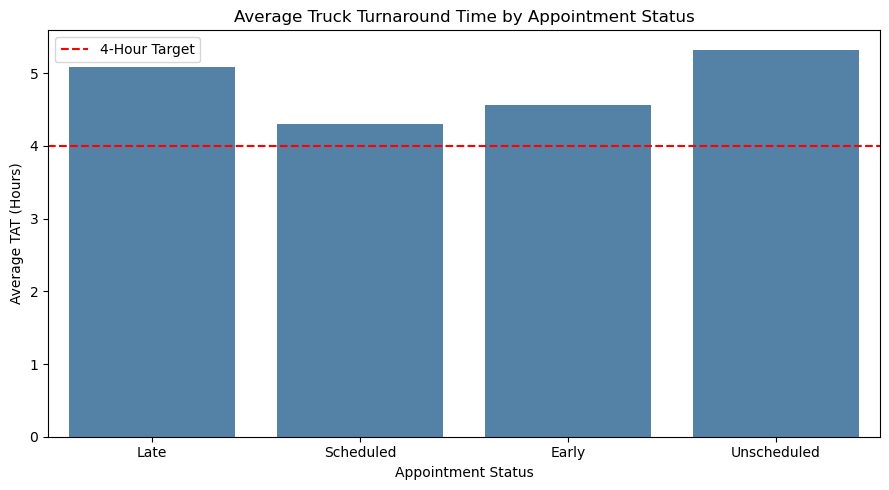

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x='Appointment_Status',
    y='Truck_Turnaround_Time_Hours',
    errorbar=None,
    color='steelblue'
)

plt.axhline(
    y=4,
    color='red',
    linestyle='--',
    label='4-Hour Target'
)

plt.title('Average Truck Turnaround Time by Appointment Status')
plt.xlabel('Appointment Status')
plt.ylabel('Average TAT (Hours)')
plt.legend()
plt.tight_layout()
plt.show()

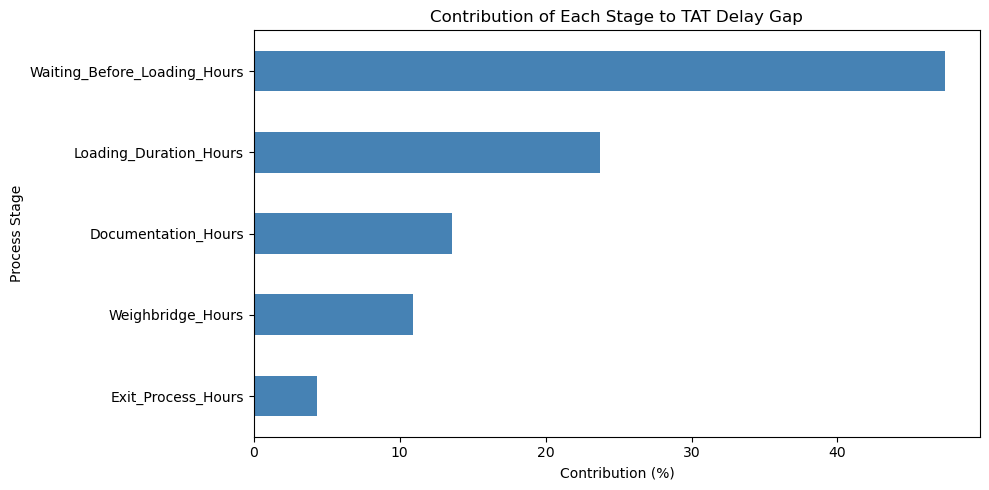

In [42]:
plt.figure(figsize=(10, 5))

contribution_pct.sort_values().plot(
    kind='barh',
    color='steelblue'
)

plt.title('Contribution of Each Stage to TAT Delay Gap')
plt.xlabel('Contribution (%)')
plt.ylabel('Process Stage')

plt.tight_layout()
plt.show()

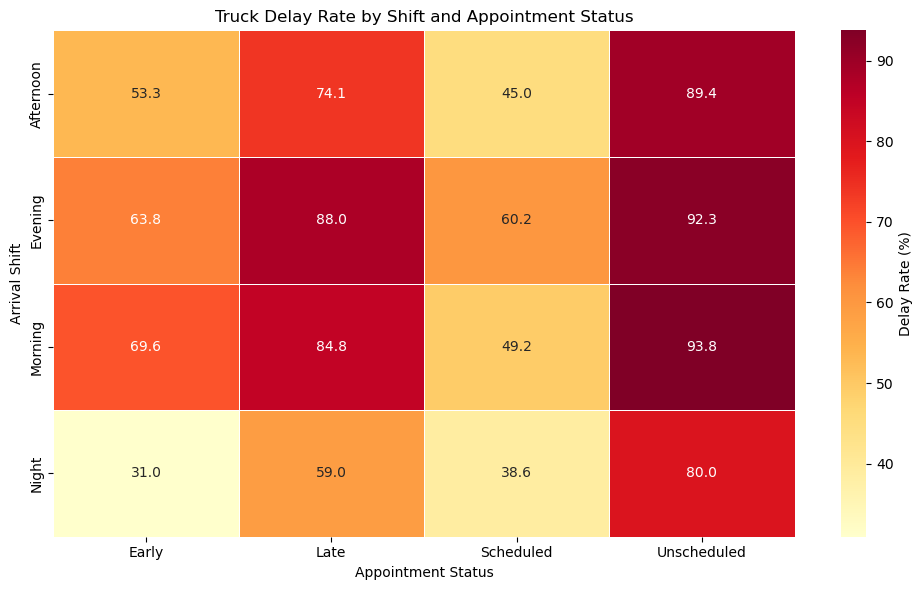

In [43]:
heatmap_data = (
    delay_rate_analysis['Delay_Rate']
    .unstack()
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=0.5,
    cbar_kws={'label': 'Delay Rate (%)'}
)

plt.title('Truck Delay Rate by Shift and Appointment Status')
plt.xlabel('Appointment Status')
plt.ylabel('Arrival Shift')

plt.tight_layout()
plt.show()

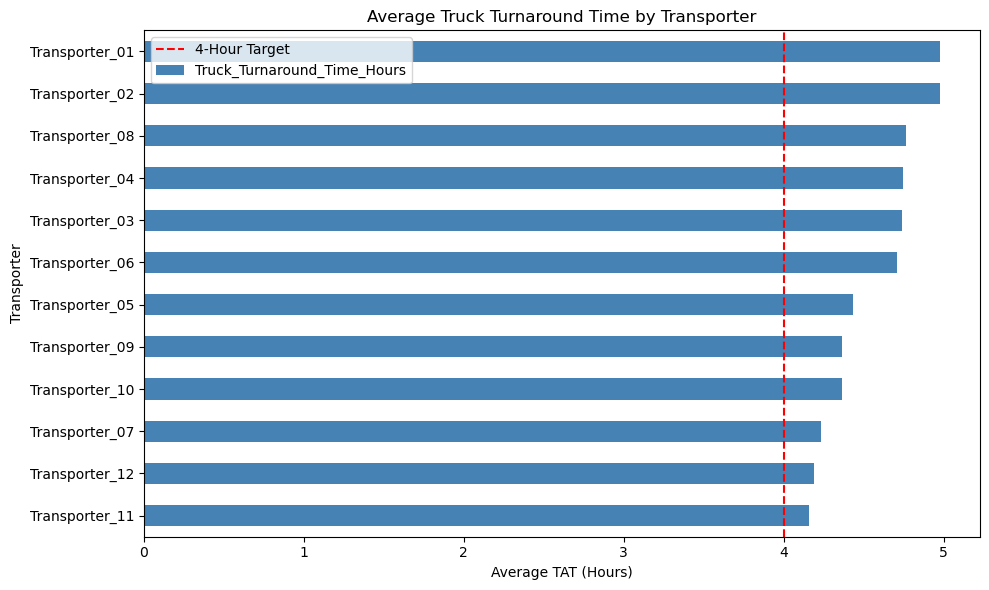

In [44]:
transporter_tat = (
    df.groupby('Transporter')
    ['Truck_Turnaround_Time_Hours']
    .mean()
    .sort_values()
)

plt.figure(figsize=(10, 6))

transporter_tat.plot(
    kind='barh',
    color='steelblue'
)

plt.axvline(
    x=4,
    color='red',
    linestyle='--',
    label='4-Hour Target'
)

plt.title('Average Truck Turnaround Time by Transporter')
plt.xlabel('Average TAT (Hours)')
plt.ylabel('Transporter')
plt.legend()

plt.tight_layout()
plt.show()

We have copmleted the visualizations for the different metrics which are required to be checked for proper business insights

Key findings
- Transporters 01 and 02 have the highest average TAT at approximately 4.98 hours.
- Transporter 11 performs best at 4.16 hours.
- All 12 transporters have an average TAT above the four-hour target.



Now we deal with the business recommendations and analyze the impact

In [45]:
#now we simulate a case where the pre-loading time is reduced by 20% to see the impact it generates

In [46]:
df['Simulated_TAT'] = (
    df['Truck_Turnaround_Time_Hours']
    - 0.20 * df['Waiting_Before_Loading_Hours']
)

current_avg = df['Truck_Turnaround_Time_Hours'].mean()
simulated_avg = df['Simulated_TAT'].mean()

current_delay_rate = (
    df['Truck_Turnaround_Time_Hours'] > 4
).mean() * 100

simulated_delay_rate = (
    df['Simulated_TAT'] > 4
).mean() * 100

print("Current Average TAT:", round(current_avg, 2))
print("Simulated Average TAT:", round(simulated_avg, 2))
print("Current Delay Rate:", round(current_delay_rate, 2), "%")
print("Simulated Delay Rate:", round(simulated_delay_rate, 2), "%")

Current Average TAT: 4.64
Simulated Average TAT: 4.27
Current Delay Rate: 60.47 %
Simulated Delay Rate: 49.47 %


Business interpretation
If pre-loading waiting time could be reduced by 20%:
- Average truck turnaround time could decrease by approximately 8%.
- The percentage of delayed trucks could decrease by 11 percentage points.
- For 1,500 trips, that represents approximately 165 fewer delayed trips.

In [47]:
df['Time_Saved_Hours'] = (
    df['Truck_Turnaround_Time_Hours']
    - df['Simulated_TAT']
)

total_hours_saved = df['Time_Saved_Hours'].sum()

avg_minutes_saved = df['Time_Saved_Hours'].mean() * 60

print("Total Truck-Hours Saved:", round(total_hours_saved, 2))
print("Average Minutes Saved Per Truck:", round(avg_minutes_saved, 2))

Total Truck-Hours Saved: 558.32
Average Minutes Saved Per Truck: 22.33


This shows that we save around 558.32 hours of total truck hours which translates to about 22.33 minutes average time saved per truck

In [48]:
#now we use an assumption that the cost of 1 truck hour is rupees 500 and do the calculation of how much money is saved in the above reduction

In [49]:
cost_per_truck_hour = 500

estimated_savings = (
    total_hours_saved * cost_per_truck_hour
)

print(
    "Estimated Cost Savings: ₹",
    round(estimated_savings, 2)
)

Estimated Cost Savings: ₹ 279158.0


Now we compile the most important operational and financial KPI's from our analysis

In [50]:
kpi_summary = pd.DataFrame({
    'Metric': [
        'Total Trips',
        'Current Average TAT (Hours)',
        'Target TAT (Hours)',
        'Current Delay Rate (%)',
        'Simulated Average TAT (Hours)',
        'Simulated Delay Rate (%)',
        'Total Truck-Hours Saved',
        'Estimated Financial Benefit (INR)'
    ],
    'Value': [
        len(df),
        round(current_avg, 2),
        4,
        round(current_delay_rate, 2),
        round(simulated_avg, 2),
        round(simulated_delay_rate, 2),
        round(total_hours_saved, 2),
        round(estimated_savings, 2)
    ]
})

kpi_summary

,Metric,Value
0,Total Trips,1500.00
1,Current Average TAT (Hours),4.64
2,Target TAT (Hours),4.00
3,Current Delay Rate (%),60.47
4,Simulated Average TAT (Hours),4.27
5,Simulated Delay Rate (%),49.47
6,Total Truck-Hours Saved,558.32
7,Estimated Financial Benefit (INR),279158.00


In [51]:
#Now what is left is to import the KPI summary and anlyzed dataset

In [52]:
import os

os.makedirs("outputs", exist_ok=True)

df.to_csv(
    "outputs/truck_turnaround_analyzed.csv",
    index=False
)


kpi_summary.to_csv(
    "outputs/kpi_summary.csv",
    index=False
)

print("Project files exported successfully!")

Project files exported successfully!


In [53]:
#Now we save the visualizations

In [63]:
import os

os.makedirs("outputs/charts", exist_ok=True)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x='Appointment_Status',
    y='Truck_Turnaround_Time_Hours',
    errorbar=None,
    color='steelblue'
)

plt.axhline(y=4, color='red', linestyle='--',
            label='4-Hour Target')

plt.title('Average TAT by Appointment Status')
plt.ylabel('Average TAT (Hours)')
plt.legend()
plt.tight_layout()

plt.savefig(charts_dir / "appointment_tat.png", dpi=300)
plt.close()

print("Chart 1 saved successfully!")

Chart 1 saved successfully!


In [64]:
plt.figure(figsize=(10, 5))

contribution_pct.sort_values().plot(
    kind='barh',
    color='steelblue'
)

plt.title('Contribution of Each Stage to TAT Delay Gap')
plt.xlabel('Contribution (%)')
plt.ylabel('Process Stage')

plt.tight_layout()

plt.savefig(
    charts_dir / "delay_contribution.png",
    dpi=300,
    bbox_inches='tight'
)

plt.close()

print("Chart 2 saved successfully!")

Chart 2 saved successfully!


In [65]:
heatmap_data = delay_rate_analysis['Delay_Rate'].unstack()

plt.figure(figsize=(10, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=0.5,
    cbar_kws={'label': 'Delay Rate (%)'}
)

plt.title('Truck Delay Rate by Shift and Appointment Status')
plt.xlabel('Appointment Status')
plt.ylabel('Arrival Shift')

plt.tight_layout()

plt.savefig(
    charts_dir / "shift_delay_heatmap.png",
    dpi=300,
    bbox_inches='tight'
)

plt.close()

print("Chart 3 saved successfully!")

Chart 3 saved successfully!


In [66]:
transporter_tat = (
    df.groupby('Transporter')
    ['Truck_Turnaround_Time_Hours']
    .mean()
    .sort_values()
)

plt.figure(figsize=(10, 6))

transporter_tat.plot(
    kind='barh',
    color='steelblue'
)

plt.axvline(
    x=4,
    color='red',
    linestyle='--',
    label='4-Hour Target'
)

plt.title('Average Truck Turnaround Time by Transporter')
plt.xlabel('Average TAT (Hours)')
plt.ylabel('Transporter')
plt.legend(loc='lower right')

plt.tight_layout()

plt.savefig(
    charts_dir / "transporter_performance.png",
    dpi=300,
    bbox_inches='tight'
)

plt.close()

print("Chart 4 saved successfully!")

Chart 4 saved successfully!


In [58]:
import os
print(os.getcwd())

c:\Users\Hello!\OneDrive\Documents\truck_TAT_RCA_Project\notebooks


In [59]:
from pathlib import Path


project_dir = Path.cwd().parent


output_dir = project_dir / "outputs"
charts_dir = output_dir / "charts"

output_dir.mkdir(exist_ok=True)
charts_dir.mkdir(exist_ok=True)

print("Output folder:", output_dir)
print("Charts folder:", charts_dir)

Output folder: c:\Users\Hello!\OneDrive\Documents\truck_TAT_RCA_Project\outputs
Charts folder: c:\Users\Hello!\OneDrive\Documents\truck_TAT_RCA_Project\outputs\charts


In [60]:
print("Existing output files:")

for file in output_dir.rglob("*"):
    if file.is_file():
        print(file.relative_to(project_dir))

Existing output files:
outputs\kpi_summary.csv
outputs\truck_turnaround_analyzed.csv
outputs\charts\appointment_tat.png
outputs\charts\delay_contribution.png
outputs\charts\shift_delay_heatmap.png
outputs\charts\transporter_performance.png


In [61]:
from pathlib import Path

project_dir = Path.cwd().parent

for folder in ["outputs", "notebooks/outputs"]:
    path = project_dir / folder
    print(f"\n{folder}:")
    if path.exists():
        for file in path.rglob("*"):
            if file.is_file():
                print(" ", file.name)
    else:
        print("Folder not found")


outputs:
  kpi_summary.csv
  truck_turnaround_analyzed.csv
  appointment_tat.png
  delay_contribution.png
  shift_delay_heatmap.png
  transporter_performance.png

notebooks/outputs:
  kpi_summary.csv
  truck_turnaround_analyzed.csv
  appointment_tat.png
  delay_contribution.png
  shift_delay_heatmap.png
  transporter_performance.png


In [62]:
output_dir.mkdir(exist_ok=True)
charts_dir.mkdir(exist_ok=True)

df.to_csv(
    output_dir / "truck_turnaround_analyzed.csv",
    index=False
)

kpi_summary.to_csv(
    output_dir / "kpi_summary.csv",
    index=False
)

print("CSV files saved successfully!")

CSV files saved successfully!
